In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Question 1

In [15]:
# 1. Create the array T 
T = np.array([
    [22, 25, 20],
    [24, 27, 21],
    [19, 20, 22],
    [25, 29, 28],
    [26, 30, 27],
    [21, 21, 23],
    [20, 26, 25],
])
cities = ["Alger", "Annaba", "Oran"]
print("T =\n", T)
 
# 2. Maxima
max_per_city = T.max(axis=0)      # one value per column (city)
max_per_day = T.max(axis=1)       # one value per row (day)
overall_max = T.max()
print("Max per city :", dict(zip(cities, max_per_city)))
print("Max per day  :", max_per_day)
print("Overall max  :", overall_max)


# 3. Day and city of maximum
day_idx, city_idx = np.unravel_index(np.argmax(T), T.shape)
print(f"Overall max = {T[day_idx, city_idx]} °C on day {day_idx + 1} in {cities[city_idx]}")


# 4. Higher temperature
higher_alger_oran = np.maximum(T[:, 0], T[:, 2])
print("max(Alger, Oran) per day :", higher_alger_oran)


# 5. Add a row with the average temperature of each city
avg_row = T.mean(axis=0)
T_with_avg = np.vstack((T, avg_row))      # result is float because of the means
print(np.round(T_with_avg, 2))
 

# 6. Days where Annaba was the hottest city
mask = (T[:, 1] > T[:, 0]) & (T[:, 1] > T[:, 2])
# print('mask = ' + mask + '\n')
days = np.where(mask)[0] + 1              # +1 because days start at 1
print("Annaba hottest on days:", days)

T =
 [[22 25 20]
 [24 27 21]
 [19 20 22]
 [25 29 28]
 [26 30 27]
 [21 21 23]
 [20 26 25]]
Max per city : {'Alger': np.int64(26), 'Annaba': np.int64(30), 'Oran': np.int64(28)}
Max per day  : [25 27 22 29 30 23 26]
Overall max  : 30
Overall max = 30 °C on day 5 in Annaba
max(Alger, Oran) per day : [22 24 22 28 27 23 25]
[[22.   25.   20.  ]
 [24.   27.   21.  ]
 [19.   20.   22.  ]
 [25.   29.   28.  ]
 [26.   30.   27.  ]
 [21.   21.   23.  ]
 [20.   26.   25.  ]
 [22.43 25.43 23.71]]
Annaba hottest on days: [1 2 4 5 7]


# Question 2

First 5 students:
 [[11 17  6 11 15]
 [ 9 13  8  4  8]
 [ 0 14  5 12  8]
 [17 19 15  8 19]
 [19  2 12  8 19]]
Mean per student (first 5): [12.   8.4  7.8 15.6 12. ]
THL | mean=9.45  median=8.5  var=39.81  std=6.31
DSS | mean=10.24  median=11.0  var=33.94  std=5.83
 DB | mean=10.32  median=10.0  var=31.72  std=5.63
 SE | mean=10.58  median=10.0  var=36.08  std=6.01
 RE | mean=10.50  median=11.0  var=36.53  std=6.04
Overall min: 0 | Overall max: 20
THL percentiles (25, 50, 75): [ 4.   8.5 15. ]
Number of grades in [10, 15]: 145
Extracted grades (first 20): [11 11 15 13 14 12 15 12 10 12 11 15 10 14 15 12 10 12 11 15]


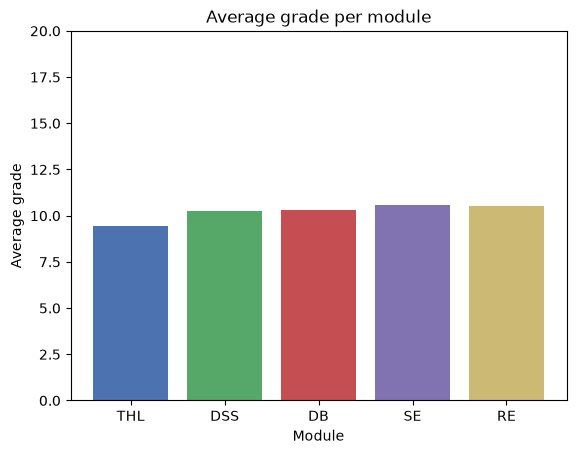

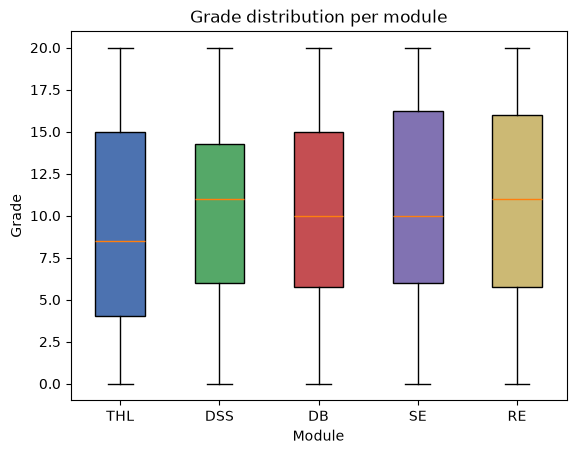

Students with all grades > 15 (indices): []
1. student #24 -> average 17.00
2. student #29 -> average 16.80
3. student #99 -> average 15.60
4. student #3 -> average 15.60
5. student #39 -> average 15.40
Best module: SE (10.58)


In [16]:
# Data initialization
np.random.seed(101)                                        
grades_of_students = np.random.randint(0, 21, size=(100, 5))  
modules = ['THL', 'DSS', 'DB', 'SE', 'RE']
print("First 5 students:\n", grades_of_students[:5])

 
# Basic statistics
mean_per_student = grades_of_students.mean(axis=1)
mean_per_module = grades_of_students.mean(axis=0)
median_per_module = np.median(grades_of_students, axis=0)
var_per_module = grades_of_students.var(axis=0)
std_per_module = grades_of_students.std(axis=0)
 
print("Mean per student (first 5):", np.round(mean_per_student[:5], 2))
for i, m in enumerate(modules):
    print(f"{m:>3} | mean={mean_per_module[i]:.2f}  median={median_per_module[i]:.1f}  "
          f"var={var_per_module[i]:.2f}  std={std_per_module[i]:.2f}")
 
print("Overall min:", grades_of_students.min(), "| Overall max:", grades_of_students.max())
 
thl = grades_of_students[:, 0]
print("THL percentiles (25, 50, 75):", np.percentile(thl, [25, 50, 75]))


# Boolean mask and filtering
mask_10_15 = (grades_of_students >= 10) & (grades_of_students <= 15)
print("Number of grades in [10, 15]:", mask_10_15.sum())     # True counts as 1
grades_10_15 = grades_of_students[mask_10_15]
print("Extracted grades (first 20):", grades_10_15[:20])

 
# Visualization: bar plot of the module averages
plt.bar(modules, mean_per_module, color=['#4C72B0', '#55A868', '#C44E52', '#8172B2', '#CCB974'])
plt.title("Average grade per module")
plt.xlabel("Module")
plt.ylabel("Average grade")
plt.ylim(0, 20)
plt.show()

 
# Visualization: box plot of the distribution per module
bp = plt.boxplot(grades_of_students, patch_artist=True)
plt.xticks(range(1, 6), modules)
for patch, color in zip(bp['boxes'], ['#4C72B0', '#55A868', '#C44E52', '#8172B2', '#CCB974']):
    patch.set_facecolor(color)
plt.title("Grade distribution per module")
plt.xlabel("Module")
plt.ylabel("Grade")
plt.show()



# Extra practice


# 1. Students with ALL grades above 15
all_above_15 = np.where((grades_of_students > 15).all(axis=1))[0]
print("Students with all grades > 15 (indices):", all_above_15)

 
# 2. Top 5 students by average grade
top5_idx = np.argsort(mean_per_student)[::-1][:5]
for rank, idx in enumerate(top5_idx, start=1):
    print(f"{rank}. student #{idx} -> average {mean_per_student[idx]:.2f}")
 
# 3. Module with the highest average
best = np.argmax(mean_per_module)
print(f"Best module: {modules[best]} ({mean_per_module[best]:.2f})")